# Organoid cut-away render (napari)

Example: patient `NF0014_T1`, well/FOV `C4-2`.

Loads the deconvolved multiplexed Cell Painting z-stack for one organoid, renders all four channels together as a 3D volume in napari, and cuts the volume with a single clipping plane to expose the interior (a "cut-away" view). It orients the camera at an oblique slant (not an axis-aligned face-on view), and exports a single screenshot PNG for use in figures.

In [1]:
import os
import pathlib

import napari
import numpy as np
from image_analysis_3D.file_utils.file_reading import (
    find_files_available,
    read_in_channels,
)
from image_analysis_3D.file_utils.notebook_init_utils import (
    bandicoot_check,
    init_notebook,
)
from napari.utils import nbscreenshot
from PIL import Image
from qtpy.QtWidgets import QApplication

In [2]:
PATIENT = "NF0014_T1"
WELL_FOV = "C4-2"

# (z, y, x) voxel scale in microns: z steps are ~10x coarser than the xy
# pixel size, matching the convention used elsewhere in this repo for
# napari 3D views (e.g. 2.segment_images/notebooks). This IS applied to
# the image layers below (`scale=SCALING_VALUES` in add_image) -- without
# it the organoid renders squashed in z by ~10x (every z step treated as
# equal to one xy pixel step), which looks "pretty flat".
#
# This repo's napari build evaluates experimental_clipping_planes in
# WORLD coordinates (i.e. post-scale), NOT raw data/array-index
# coordinates -- clip_position below is scaled by SCALING_VALUES to
# match. If the clip-away export comes out black again, that mismatch is
# the first thing to re-check (set DEBUG_DISABLE_CLIP = True and confirm
# the unclipped render looks right first).
SCALING_VALUES = [1, 0.1, 0.1]

# render headless (no interactive window) when running as a script
headless = False

# set True to skip applying the clip (debug: isolates whether a black
# canvas is caused by clipping vs. the camera/contrast)
DEBUG_DISABLE_CLIP = False

PERCENTILE_CLIP = 99.9

# Cell Painting channel metadata: filename token -> (channel key, napari colormap)
CHANNEL_INFO = {
    "405": {"key": "DNA", "colormap": "cyan"},
    "488": {"key": "ER", "colormap": "green"},
    "555": {"key": "AGP", "colormap": "magenta"},
    "640": {"key": "Mito", "colormap": "red"},
}

# camera orientation for the exported view: a 3/4 slant, not a flat
# axis-aligned face (viewer.camera.angles is (z, y, x) axis rotation, degrees)
CAMERA_ANGLES = (-26.466971148077874, 3.2209926853945543, 139.04465173311866)
CAMERA_ZOOM = 1

# clean cut-away: a single clipping plane through the volume's (y, x)
# center, with no z component, so the same cut is applied at every z
# slice -- the full depth of the organoid. CLIP_NORMAL points toward the
# half that is KEPT; the near side (opposite the normal) is clipped away.
# (0, 0, 1) cuts straight along the x axis, keeping x >= x_center.
CLIP_NORMAL = (0.0, 0.0, 1.0)

OUTPUT_PATH = pathlib.Path(
    f"../montages/organoid_cutaway_{PATIENT}_{WELL_FOV}.png"
).resolve()

## Get the paths

In [3]:
root_dir, in_notebook = init_notebook()

image_base_dir = bandicoot_check(
    pathlib.Path(os.path.expanduser("~/mnt/bandicoot")).resolve(), root_dir
)
image_base_dir = image_base_dir / "data"

# use the deconvolved 3D z-stacks so the full volume (not a 2D projection)
# is available to render and cut away in napari
well_fov_dir = pathlib.Path(
    f"{image_base_dir}/{PATIENT}/deconvolved_images/{WELL_FOV}"
).resolve(strict=True)
well_fov_dir

PosixPath('/home/lippincm/mnt/bandicoot/NF1_organoid_data/data/NF0014_T1/deconvolved_images/C4-2')

## Load the multiplexed z-stack

In [4]:
channel_dict = {info["key"]: suffix for suffix, info in CHANNEL_INFO.items()}
channel_stacks = read_in_channels(
    find_files_available(well_fov_dir),
    channel_dict=channel_dict,
    channels_to_read=list(channel_dict.keys()),
)

for key, stack in channel_stacks.items():
    if stack is None:
        raise FileNotFoundError(
            f"No deconvolved image found for channel '{key}' in {well_fov_dir}"
        )

{key: stack.shape for key, stack in channel_stacks.items()}

{'DNA': (33, 1537, 1540),
 'ER': (33, 1537, 1540),
 'AGP': (33, 1537, 1540),
 'Mito': (33, 1537, 1540)}

In [5]:
# data-driven display contrast: scale each channel so its
# PERCENTILE_CLIP-th percentile pixel value sits near the top of its
# display range, the same approach used in
# ../notebooks/cell_painting_assay_montage.ipynb
contrast_by_key = {
    key: (0.0, float(np.percentile(stack, PERCENTILE_CLIP)))
    for key, stack in channel_stacks.items()
}
contrast_by_key["DNA"] = (2355.8190476190475, 13019.0)
contrast_by_key["ER"] = (1838.5714285714284, 7722.0)
contrast_by_key["AGP"] = (2912.3809523809523, 7645.0)
contrast_by_key["Mito"] = (179.04761904761904, 940.0)

## View in napari — slanted cut-away render

In [6]:
viewer = napari.Viewer(ndisplay=3, show=bool(not headless))

colormap_by_key = {info["key"]: info["colormap"] for info in CHANNEL_INFO.values()}

image_metadata = f"{PATIENT}_{WELL_FOV}"
for key, stack in channel_stacks.items():
    viewer.add_image(
        stack,
        name=f"{image_metadata}_{key}",
        colormap=colormap_by_key[key],
        contrast_limits=contrast_by_key[key],
        scale=SCALING_VALUES,
        blending="additive",
        rendering="mip",
    )

In [7]:
# IMPORTANT: reset_view() re-fits the camera to the data and resets
# camera.angles back to its default orientation, so it must run BEFORE the
# slant is applied -- setting angles first and reset_view()-ing after wipes
# the slant right back out (this was a bug in an earlier version of this
# cell and produced a blank/black export).
viewer.dims.ndisplay = 3
viewer.reset_view()
viewer.camera.angles = CAMERA_ANGLES
viewer.camera.zoom *= CAMERA_ZOOM

# flush the Qt event loop so the canvas actually repaints the new
# camera/clip state before anything tries to screenshot it
for _ in range(5):
    QApplication.processEvents()

## Export the figure PNG

In [8]:
# sanity check: if this prints all-zero max intensities, or a clip
# plane is hiding everything, the export below will come out black --
# fix contrast/clip/camera above before re-running the export cell.
for layer in viewer.layers:
    print(layer.name, "max intensity:", layer.data.max(), "visible:", layer.visible)
print("camera center:", viewer.camera.center)
print("camera zoom:", viewer.camera.zoom)
print("camera angles:", viewer.camera.angles)

NF0014_T1_C4-2_DNA max intensity: 65535 visible: True
NF0014_T1_C4-2_ER max intensity: 65535 visible: True
NF0014_T1_C4-2_AGP max intensity: 65535 visible: True
NF0014_T1_C4-2_Mito max intensity: 65535 visible: True
camera center: (16.0, 76.80000000000001, 76.95000000000002)
camera zoom: 8.13402732595966
camera angles: (-26.466971148077874, 3.2209926853945543, 139.04465173311866)


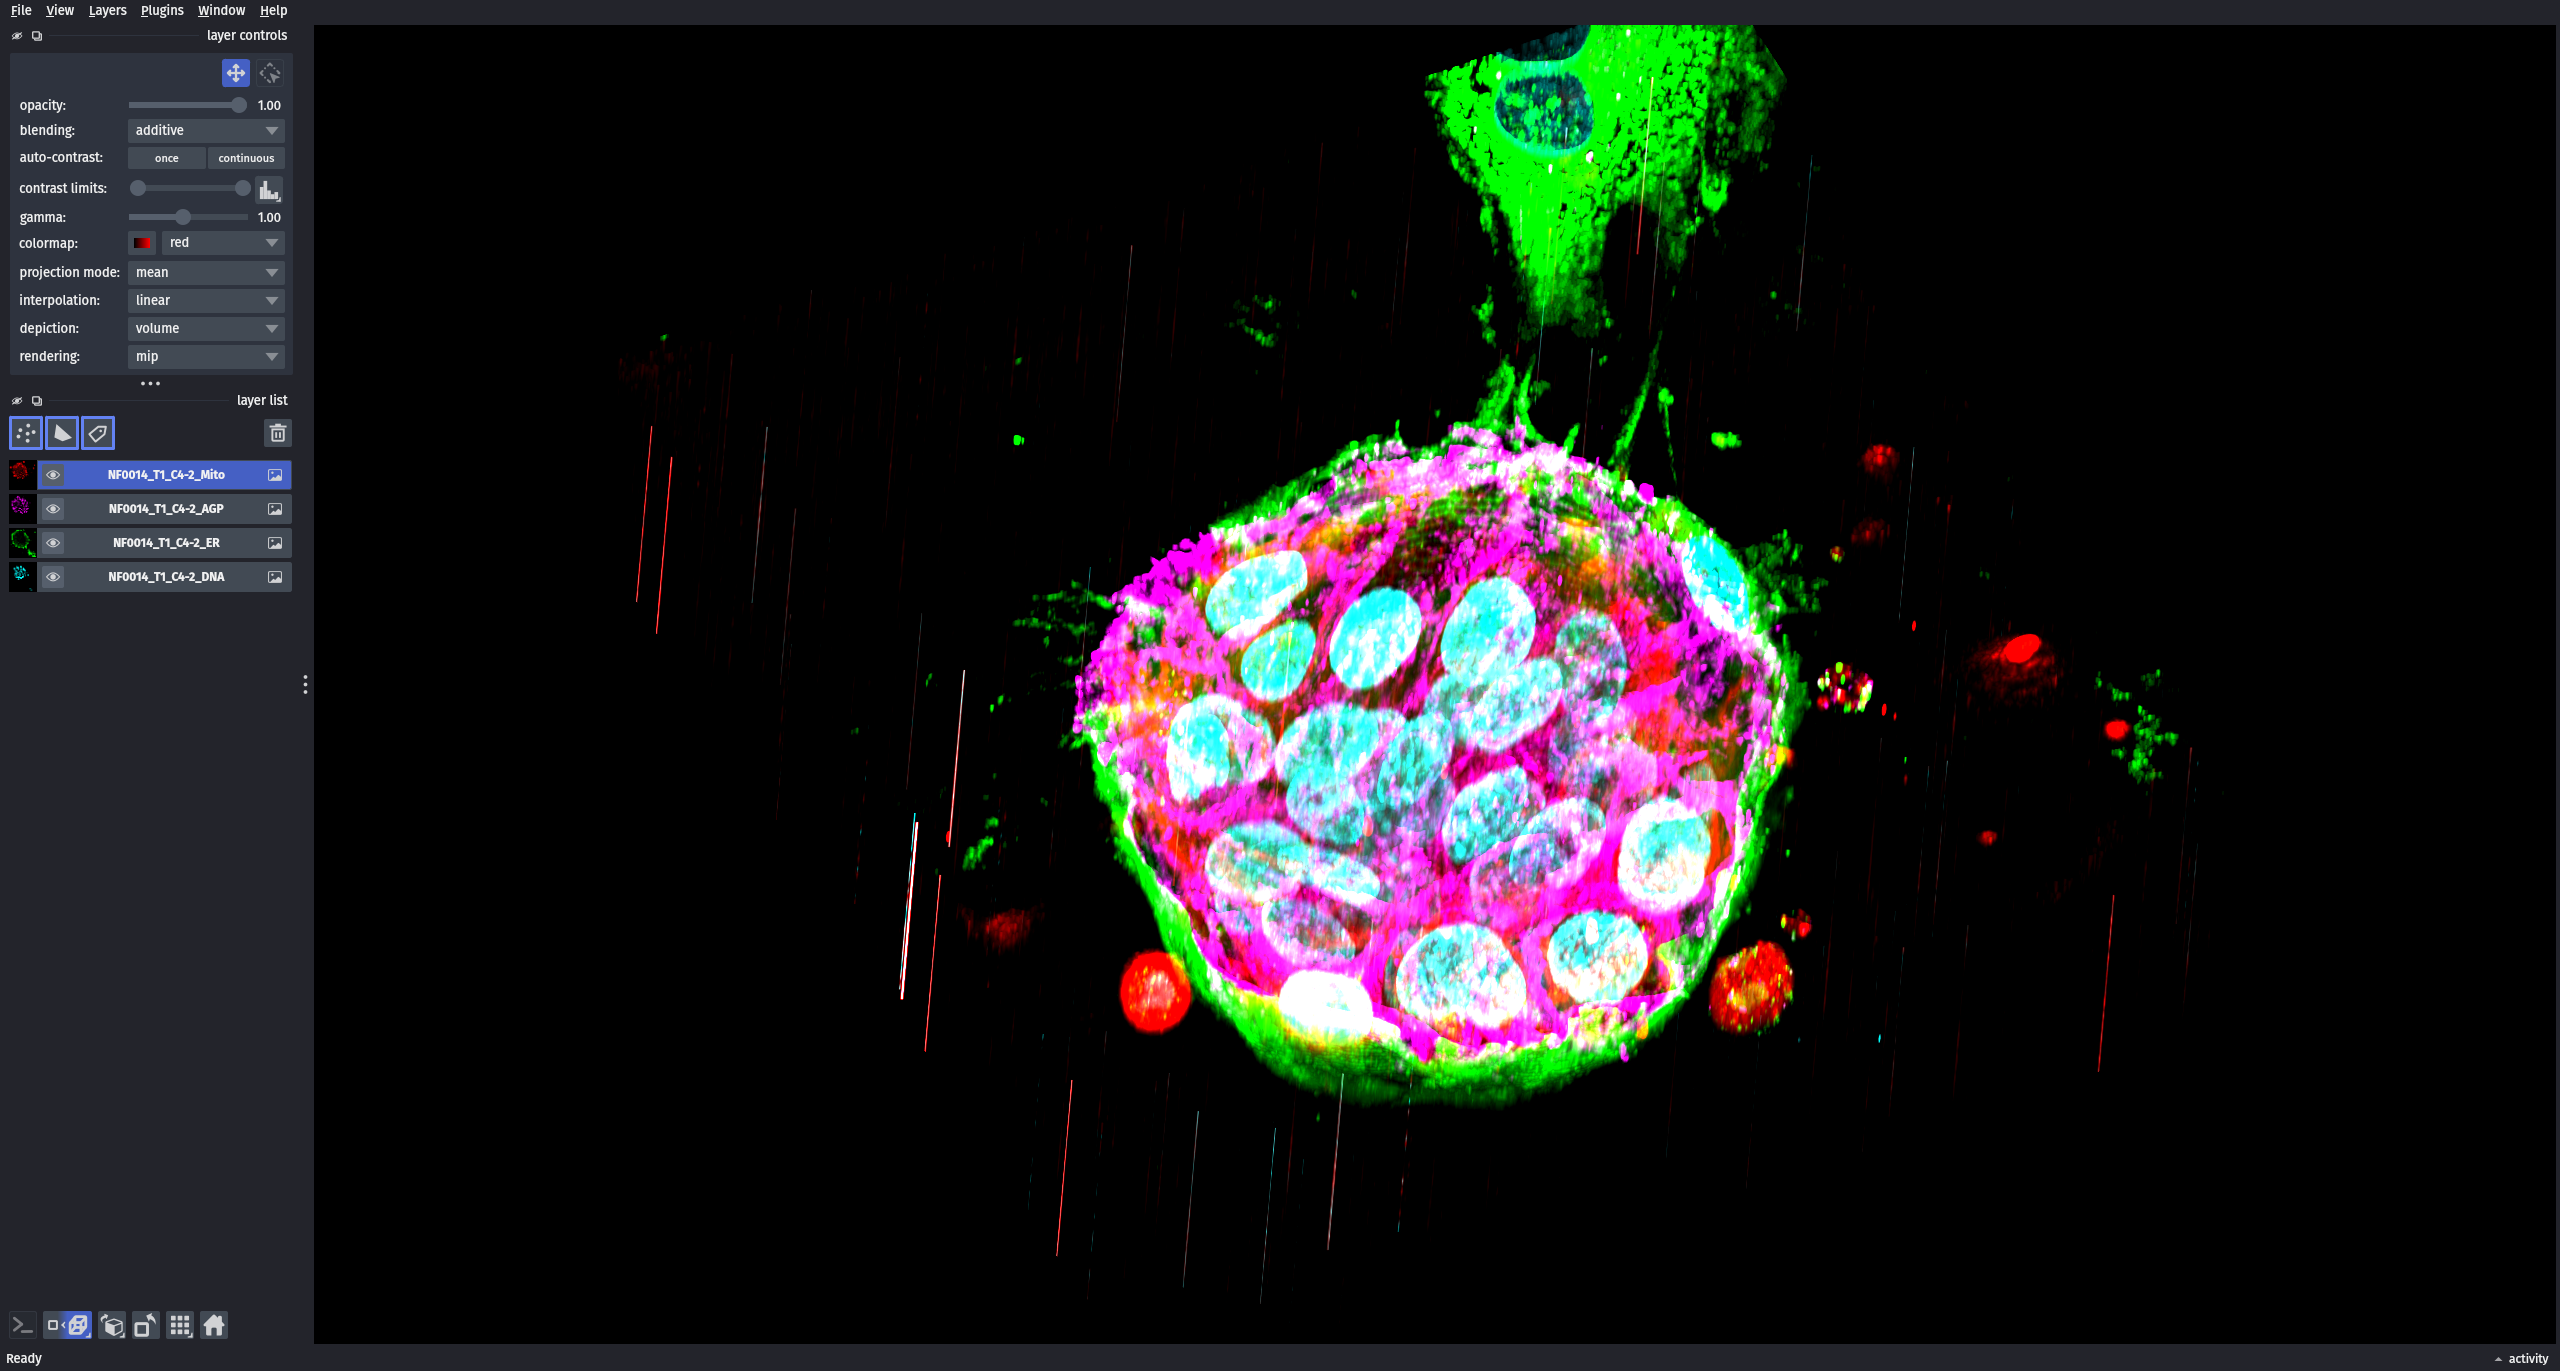

In [9]:
screenshot = nbscreenshot(viewer)
screenshot

In [10]:
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
for _ in range(5):
    QApplication.processEvents()
screenshot_array = viewer.screenshot(canvas_only=True, flash=False)
print("screenshot max pixel value:", screenshot_array.max())
Image.fromarray(screenshot_array).save(OUTPUT_PATH)
OUTPUT_PATH

screenshot max pixel value: 255


PosixPath('/home/lippincm/Documents/NF1_3D_organoid_profiling_pipeline/figures/montage/montages/organoid_cutaway_NF0014_T1_C4-2.png')

In [11]:
viewer.close()